In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sqlalchemy import create_engine

In [2]:
engine = create_engine(
    "postgresql+psycopg2://localhost/olist_analytics"
)

In [3]:
pd.read_sql(
    """
    SELECT COUNT(*) AS rows
    FROM analytics.order_mart
    """,
    engine
)

,rows
0,99441


# 1. Late Delivery vs Review Score

This section tests whether delivered orders arriving late are associated with systematically different customer review scores from orders delivered on time.

Because review score is ordinal (1–5) and does not require a normality assumption, the analysis uses the Mann–Whitney U test together with rank-biserial correlation as an effect-size measure.

In [4]:
delivery_reviews = pd.read_sql(
    """
    SELECT
        late_delivery_flag,
        latest_review_score
    FROM analytics.order_mart
    WHERE is_delivered = TRUE
      AND late_delivery_flag IS NOT NULL
      AND latest_review_score IS NOT NULL
    """,
    engine
)

delivery_reviews.head()

,late_delivery_flag,latest_review_score
0,False,5
1,False,4
2,False,5
3,False,4
4,False,5


In [5]:
delivery_reviews.info()
delivery_reviews["late_delivery_flag"].value_counts()
delivery_reviews["latest_review_score"].value_counts().sort_index()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95801 entries, 0 to 95800
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   late_delivery_flag   95801 non-null  bool 
 1   latest_review_score  95801 non-null  int64
dtypes: bool(1), int64(1)
memory usage: 842.1 KB


latest_review_score
1     9343
2     2918
3     7913
4    18884
5    56743
Name: count, dtype: int64

In [6]:
delivery_summary = (
    delivery_reviews
    .groupby("late_delivery_flag")["latest_review_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .round(2)
)

delivery_summary

review_distribution = pd.crosstab(
    delivery_reviews["late_delivery_flag"],
    delivery_reviews["latest_review_score"],
    normalize="index"
).round(4)

review_distribution

latest_review_score,1,2,3,4,5
late_delivery_flag,,,,,
False,0.0658,0.0263,0.0799,0.2035,0.6245
True,0.4621,0.0786,0.1138,0.1232,0.2223


In [7]:
late_reviews = delivery_reviews.loc[
    delivery_reviews["late_delivery_flag"] == True,
    "latest_review_score"
]

on_time_reviews = delivery_reviews.loc[
    delivery_reviews["late_delivery_flag"] == False,
    "latest_review_score"
]

u_stat, p_value = stats.mannwhitneyu(
    late_reviews,
    on_time_reviews,
    alternative="two-sided"
)

print(f"Mann–Whitney U statistic: {u_stat:,.0f}")
print(f"p-value: {p_value:.6g}")

Mann–Whitney U statistic: 150,626,056
p-value: 0


In [8]:
n_late = len(late_reviews)
n_on_time = len(on_time_reviews)

rank_biserial = (
    2 * u_stat / (n_late * n_on_time)
) - 1

print(f"Late orders: {n_late:,}")
print(f"On-time orders: {n_on_time:,}")
print(f"Rank-biserial correlation: {rank_biserial:.3f}")

Late orders: 7,661
On-time orders: 88,140
Rank-biserial correlation: -0.554


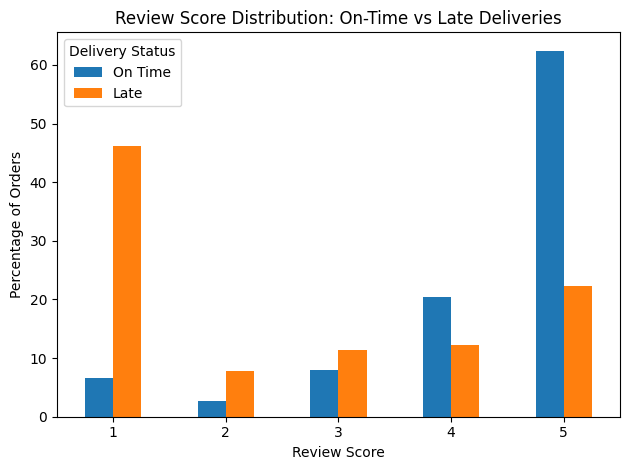

In [10]:
plot_data = review_distribution.copy() * 100

plot_data.index = plot_data.index.map({
    False: "On Time",
    True: "Late"
})

plot_data = plot_data.T

plot_data.plot(kind="bar")

plt.xlabel("Review Score")
plt.ylabel("Percentage of Orders")
plt.title("Review Score Distribution: On-Time vs Late Deliveries")
plt.xticks(rotation=0)
plt.legend(title="Delivery Status")
plt.tight_layout()
plt.show()

### Interpretation

Late delivery is strongly associated with lower customer review scores.

The Mann–Whitney U test indicates a statistically significant difference in review-score distributions between late and on-time deliveries (p < 0.001). The rank-biserial correlation of -0.554 indicates a large negative association, showing that late orders tend to receive substantially lower ratings.

The difference is also commercially meaningful rather than merely statistically significant. Approximately 46.2% of late orders received a 1-star review, compared with only 6.6% of on-time orders. Conversely, 62.5% of on-time orders received 5 stars, compared with 22.2% of late orders.

These results provide strong evidence that delivery performance is associated with customer satisfaction. However, because this is observational data, the analysis does not establish that late delivery alone causes lower review scores.

# 2. Delivery Duration vs Review Score

This section examines whether longer delivery times are associated with lower customer review scores.

Because delivery duration is skewed and review score is ordinal, Spearman's rank correlation is used rather than Pearson correlation.

In [11]:
delivery_duration = pd.read_sql(
    """
    SELECT
        delivery_days,
        latest_review_score
    FROM analytics.order_mart
    WHERE is_delivered = TRUE
      AND delivery_days IS NOT NULL
      AND latest_review_score IS NOT NULL
    """,
    engine
)

delivery_duration.describe()

,delivery_days,latest_review_score
count,95801.000000,95801.000000
mean,12.518118,4.156209
std,9.460925,1.284553
min,0.530000,1.000000
25%,6.760000,4.000000
50%,10.210000,5.000000
75%,15.670000,5.000000
max,208.350000,5.000000


In [12]:
spearman_rho, spearman_p = stats.spearmanr(
    delivery_duration["delivery_days"],
    delivery_duration["latest_review_score"]
)

print(f"Spearman correlation: {spearman_rho:.3f}")
print(f"p-value: {spearman_p:.6g}")

Spearman correlation: -0.235
p-value: 0


In [13]:
delivery_duration["delivery_band"] = pd.cut(
    delivery_duration["delivery_days"],
    bins=[0, 5, 10, 15, 20, 30, np.inf],
    labels=[
        "0-5 days",
        "6-10 days",
        "11-15 days",
        "16-20 days",
        "21-30 days",
        "30+ days"
    ],
    include_lowest=True
)

delivery_band_summary = (
    delivery_duration
    .groupby("delivery_band", observed=True)
    .agg(
        orders=("latest_review_score", "count"),
        avg_review=("latest_review_score", "mean"),
        median_review=("latest_review_score", "median")
    )
    .round(2)
)

delivery_band_summary

,orders,avg_review,median_review
delivery_band,,,
0-5 days,13407,4.45,5.0
6-10 days,32880,4.36,5.0
11-15 days,23435,4.27,5.0
16-20 days,12083,4.13,5.0
21-30 days,9568,3.68,4.0
30+ days,4428,2.25,1.0


### Interpretation

Delivery duration is negatively associated with customer review score (Spearman ρ = -0.235, p < 0.001). The association is statistically significant but modest in magnitude, indicating that delivery time is related to customer satisfaction without fully explaining variation in review scores.

The grouped results suggest a nonlinear deterioration in customer experience. Average reviews decline gradually from 4.45 for deliveries within 5 days to 4.13 for deliveries taking 16–20 days, before falling more sharply to 3.68 for 21–30 day deliveries and 2.25 for deliveries exceeding 30 days.

Together with the late-delivery analysis, the results suggest that severe fulfilment delays are particularly associated with poor customer satisfaction. As the dataset is observational, these associations should not be interpreted as causal effects.

# 3. First-Order Characteristics vs 1–90 Day Customer Return

This section evaluates whether characteristics of a customer's first delivered order differ between customers who subsequently return within 1–90 days and those who do not.

Only customers with at least 90 days of observable follow-up are included to reduce right-censoring. Second purchases occurring within 24 hours are excluded from the return definition because they may represent split purchases or continuation of the same shopping session rather than genuine customer retention.

In [16]:
retention = pd.read_sql(
    """
    SELECT
        customer_unique_id,

        CASE
            WHEN days_to_second_purchase >= 1
             AND days_to_second_purchase <= 90
            THEN TRUE
            ELSE FALSE
        END AS returned_1_to_90d,

        first_order_gmv,
        first_order_freight_ratio,
        first_order_item_count,
        first_order_review_score,
        first_order_delivery_days,
        first_order_late_flag,
        first_order_payment_type,
        first_order_category

    FROM analytics.customer_mart

    WHERE eligible_90d_followup = TRUE
    """,
    engine
)

retention.shape

(75387, 10)

In [17]:
retention["returned_1_to_90d"].value_counts()

returned_1_to_90d
False    74455
True       932
Name: count, dtype: int64

In [18]:
continuous_vars = [
    "first_order_gmv",
    "first_order_freight_ratio",
    "first_order_item_count",
    "first_order_review_score",
    "first_order_delivery_days"
]

retention_summary = (
    retention
    .groupby("returned_1_to_90d")[continuous_vars]
    .mean()
    .T
    .round(3)
)

retention_summary.columns = [
    "Did Not Return",
    "Returned 1-90d"
]

retention_summary

,Did Not Return,Returned 1-90d
first_order_gmv,137.489,128.641
first_order_freight_ratio,0.304,0.303
first_order_item_count,1.141,1.238
first_order_review_score,4.114,4.274
first_order_delivery_days,13.526,12.043


In [21]:
def mann_whitney_with_effect(df, variable, group_col="returned_1_to_90d"):
    non_returners = df.loc[
        df[group_col] == False,
        variable
    ].dropna()

    returners = df.loc[
        df[group_col] == True,
        variable
    ].dropna()

    u_stat, p_value = stats.mannwhitneyu(
        returners,
        non_returners,
        alternative="two-sided"
    )

    rank_biserial = (
        2 * u_stat / (len(returners) * len(non_returners))
    ) - 1

    return {
        "variable": variable,
        "n_returners": len(returners),
        "n_non_returners": len(non_returners),
        "returner_mean": returners.mean(),
        "non_returner_mean": non_returners.mean(),
        "u_stat": u_stat,
        "p_value": p_value,
        "rank_biserial": rank_biserial
    }

test_results = pd.DataFrame([
    mann_whitney_with_effect(retention, variable)
    for variable in continuous_vars
])

test_results[
    [
        "variable",
        "n_returners",
        "n_non_returners",
        "returner_mean",
        "non_returner_mean",
        "p_value",
        "rank_biserial"
    ]
].round(4)

,variable,n_returners,n_non_returners,returner_mean,non_returner_mean,p_value,rank_biserial
0,first_order_gmv,932,74455,128.6409,137.4892,0.7338,-0.0065
1,first_order_freight_ratio,932,74455,0.3030,0.3045,0.6154,0.0096
2,first_order_item_count,932,74455,1.2382,1.1406,0.0000,0.0403
3,first_order_review_score,929,73925,4.2745,4.1145,0.0001,0.0686
4,first_order_delivery_days,932,74432,12.0427,13.5262,0.0000,-0.0825


In [24]:
late_return = retention[
    retention["first_order_late_flag"].notna()
].copy()

contingency = pd.crosstab(
    late_return["first_order_late_flag"],
    late_return["returned_1_to_90d"]
)

contingency

returned_1_to_90d,False,True
first_order_late_flag,,
False,67887,868
True,6545,64


In [25]:
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency
)

n = contingency.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 /
    (
        n * min(
            contingency.shape[0] - 1,
            contingency.shape[1] - 1
        )
    )
)

print(f"Chi-square: {chi2:.3f}")
print(f"p-value: {p_value:.6g}")
print(f"Cramér's V: {cramers_v:.3f}")

Chi-square: 4.032
p-value: 0.0446486
Cramér's V: 0.007


In [26]:
late_return_rates = (
    late_return
    .groupby("first_order_late_flag")["returned_1_to_90d"]
    .agg(
        customers="count",
        returners="sum",
        return_rate="mean"
    )
)

late_return_rates["return_rate_pct"] = (
    late_return_rates["return_rate"] * 100
)

late_return_rates.round(3)

,customers,returners,return_rate,return_rate_pct
first_order_late_flag,,,,
False,68755,868,0.013,1.262
True,6609,64,0.010,0.968


### Interpretation

First-order characteristics showed limited ability to distinguish customers who returned within 1–90 days from those who did not.

First-order GMV and freight burden showed no statistically meaningful differences between the two groups. Returners placed slightly larger baskets by item count, gave somewhat higher review scores, and experienced shorter delivery times, but the corresponding effect sizes were small.

Late first deliveries were associated with a lower observed 1–90 day return rate (0.97%) than on-time deliveries (1.26%). Although the chi-square test was statistically significant (p = 0.045), Cramér's V was only 0.007, indicating a negligible practical association.

This contrasts sharply with the relationship between late delivery and review score, where the effect was large. The results therefore suggest that fulfilment performance is strongly associated with immediate customer satisfaction but is only weakly associated with subsequent purchasing behaviour in this dataset.

Because this analysis is observational, these relationships should not be interpreted as causal effects.

# 4. Categorical Characteristics vs Customer Return

This section tests whether categorical first-order characteristics, including payment method and product category, are associated with 1–90 day customer return behaviour.

Chi-square tests are used to test independence, while Cramér's V is reported to assess the practical strength of each association.

In [27]:
payment_data = retention[
    retention["first_order_payment_type"].notna()
].copy()

payment_table = pd.crosstab(
    payment_data["first_order_payment_type"],
    payment_data["returned_1_to_90d"]
)

payment_table

returned_1_to_90d,False,True
first_order_payment_type,,
boleto,15129,182
credit_card,56230,704
debit_card,771,11
voucher,2324,35


In [28]:
chi2_payment, p_payment, dof_payment, expected_payment = (
    stats.chi2_contingency(payment_table)
)

n_payment = payment_table.to_numpy().sum()

cramers_v_payment = np.sqrt(
    chi2_payment
    /
    (
        n_payment
        * min(
            payment_table.shape[0] - 1,
            payment_table.shape[1] - 1
        )
    )
)

print(f"Chi-square: {chi2_payment:.3f}")
print(f"p-value: {p_payment:.6g}")
print(f"Cramér's V: {cramers_v_payment:.3f}")

Chi-square: 1.652
p-value: 0.647557
Cramér's V: 0.005


In [29]:
payment_return_rates = (
    payment_data
    .groupby("first_order_payment_type")["returned_1_to_90d"]
    .agg(
        customers="count",
        returners="sum",
        return_rate="mean"
    )
)

payment_return_rates["return_rate_pct"] = (
    payment_return_rates["return_rate"] * 100
)

payment_return_rates.round(3)

,customers,returners,return_rate,return_rate_pct
first_order_payment_type,,,,
boleto,15311,182,0.012,1.189
credit_card,56934,704,0.012,1.237
debit_card,782,11,0.014,1.407
voucher,2359,35,0.015,1.484


In [32]:
category_counts = (
    retention["first_order_category"]
    .value_counts()
)

eligible_categories = category_counts[
    category_counts >= 200
].index

category_data = retention[
    retention["first_order_category"].isin(
        eligible_categories
    )
].copy()

category_table = pd.crosstab(
    category_data["first_order_category"],
    category_data["returned_1_to_90d"]
)

chi2_category, p_category, dof_category, expected_category = (
    stats.chi2_contingency(category_table)
)

n_category = category_table.to_numpy().sum()

cramers_v_category = np.sqrt(
    chi2_category
    /
    (
        n_category
        * min(
            category_table.shape[0] - 1,
            category_table.shape[1] - 1
        )
    )
)

print(f"Chi-square: {chi2_category:.3f}")
print(f"p-value: {p_category:.6g}")
print(f"Cramér's V: {cramers_v_category:.3f}")

Chi-square: 89.025
p-value: 8.11669e-07
Cramér's V: 0.035


In [33]:
category_return_rates = (
    category_data
    .groupby("first_order_category")["returned_1_to_90d"]
    .agg(
        customers="count",
        returners="sum",
        return_rate="mean"
    )
)

category_return_rates["return_rate_pct"] = (
    category_return_rates["return_rate"] * 100
)

category_return_rates.sort_values(
    "return_rate_pct",
    ascending=False
).round(3)

,customers,returners,return_rate,return_rate_pct
first_order_category,,,,
drinks,202,8,0.040,3.960
home_confort,294,7,0.024,2.381
fashion_bags_accessories,1435,29,0.020,2.021
bed_bath_table,7135,130,0.018,1.822
construction_tools_construction,389,7,0.018,1.799
furniture_living_room,284,5,0.018,1.761
home_construction,304,5,0.016,1.645
market_place,245,4,0.016,1.633
sports_leisure,6044,96,0.016,1.588


### Interpretation

First-order payment method was not meaningfully associated with 1–90 day customer return behaviour. The chi-square test was not statistically significant (p = 0.648), and Cramér's V was only 0.005, indicating essentially no relationship.

Product category showed a statistically significant association with subsequent return behaviour (p < 0.001), although the overall effect size was weak (Cramér's V = 0.035). Return rates varied across categories, but some of the highest observed rates were based on relatively small customer samples.

Larger categories such as bed/bath/table and sports/leisure provide more stable evidence of category-level differences than smaller groups. Overall, category appears somewhat more informative for retention behaviour than payment method, but it does not strongly explain whether an individual customer returns.